# HW 3 Trains

df1: We classify class=1 and class=2 as the same type of accident --> binary
df2: We classify three distinct classes
--> we run multinomial
--> we run ordinal

For multinomial, class = 0 and class = 1 and class = 2 are all distinct

For ordinal, we assume accident type 2 is worse than acciden type 1, so: 2>1>0

We remove FIRM feature
    df3a: class=1 and class=2 are the same --> binary
    df3b: three distinct
    --> multinomial
    --> ordinal

Rough Sketch:

function to clean data a specific way
--> create each data frame

function to run binary logistic model
    model
    cf matrix
    graph ROC-AUC


function to run multinomial logistic model
    model
    cf matrix
    graph ROC-AUC


function to run ordinal logistic model
    model
    cf matrix
    graph ROC-AUC

### Data Cleaning

In [201]:
import pandas as pd

df = pd.read_csv('FRAFirm.csv')
df.info()
df.head()

df.shape


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38759 entries, 0 to 38758
Data columns (total 23 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   FIRM      38759 non-null  int64  
 1   class     38759 non-null  int64  
 2   Start     38759 non-null  int64  
 3   End       38759 non-null  int64  
 4   Length    38759 non-null  int64  
 5   Night     38759 non-null  int64  
 6   Gap       38759 non-null  int64  
 7   WS        38759 non-null  int64  
 8   idx       38759 non-null  int64  
 9   Base      38759 non-null  float64
 10  StartAdj  38759 non-null  float64
 11  LenAdj    38759 non-null  float64
 12  Comp      38759 non-null  float64
 13  Trans     38759 non-null  float64
 14  Press     38759 non-null  float64
 15  p1s       38759 non-null  int64  
 16  p1l       38759 non-null  int64  
 17  p2s       38759 non-null  int64  
 18  p2l       38759 non-null  int64  
 19  MalAdj    38759 non-null  int64  
 20  NFZ       38759 non-null  in

(38759, 23)

no categorical data; want to check for NA, duplicates, and distribution of numerical data

In [202]:
sum(df.duplicated())

1453

In [203]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import exp
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import scale
from sklearn import preprocessing
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

import matplotlib.colors as mcolors

In [204]:
df.drop_duplicates(inplace = True)
df.shape

prop = df["class"].value_counts()
print(prop)

class
0    34862
1     1779
2      665
Name: count, dtype: int64


In [205]:
# df1 = for binomial logistic regression where an accident is an accident no matter the type
df1 = df.copy() 
# need stuff here to combine 1 and 2 into one class
df1['class'] = df1['class'].replace({1: 1, 2: 1 })

prop = df1["class"].value_counts()
print(prop)

y1 = df1['class']
X1 = df1.iloc[:, df1.columns != 'class']

X_train1, X_test1, y_train1, y_test1 = train_test_split(X1, y1, test_size=0.20, random_state=12, stratify=y)

class
0    34862
1     2444
Name: count, dtype: int64


In [206]:
# df2 = all three types are distinct. we run this df in both multinomial and ordinal
df2 = df.copy() 
# need stuff here to combine 1 and 2 into one class
y2 = df2['class']
X2 = df2.iloc[:, df2.columns != 'class']

prop2 = df2["class"].value_counts()
print(prop2)

X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.20, random_state=12, stratify=y2)

class
0    34862
1     1779
2      665
Name: count, dtype: int64


In [207]:
df3 = df.drop(["FIRM"], axis=1)
# df3a = binomial without FIRM
df3a = df3.copy() # combine classes again
df3a['class'] = df3a['class'].replace({1: 1, 2: 1 })

y3a = df3a['class']
X3a = df3a.iloc[:, df3a.columns != 'class']

X_train3a, X_test3a, y_train3a, y_test3a = train_test_split(X3a, y3a, test_size=0.20, random_state=12, stratify=y3a)


# df3b = multi and ordinal without FIRM
df3b = df3.copy()

y3b = df3b['class']
X3b = df3b.iloc[:, df3b.columns != 'class']

X_train3b, X_test3b, y_train3b, y_test3b = train_test_split(X3b, y3b, test_size=0.20, random_state=12, stratify=y3b)

### Modelling Logistic Regression

binom_func = takes in dfs with class = 0,1
3p_func = takes in 3 parameters for class

both have threshold of 30 (we prefer flse positives over false negatives)

we compare all 6 outputs

In [208]:
def eda(df):
    colors = list(mcolors.CSS4_COLORS.keys())[10:]
    fig = plt.figure(figsize=(20,20))
    for i, feature in enumerate(df.columns):
        f = fig.add_subplot(8, 4, i + 1)
        df[feature].hist(bins = 20, ax = f, facecolor = colors[i])
        f.set_title(feature + " Histogram", color = colors[35])
        f.set_yscale('log')
    fig.tight_layout()
    plt.show()

    plt.figure(figsize = (38, 16))
    sns.heatmap(df.corr(), annot = True)
    plt.show()

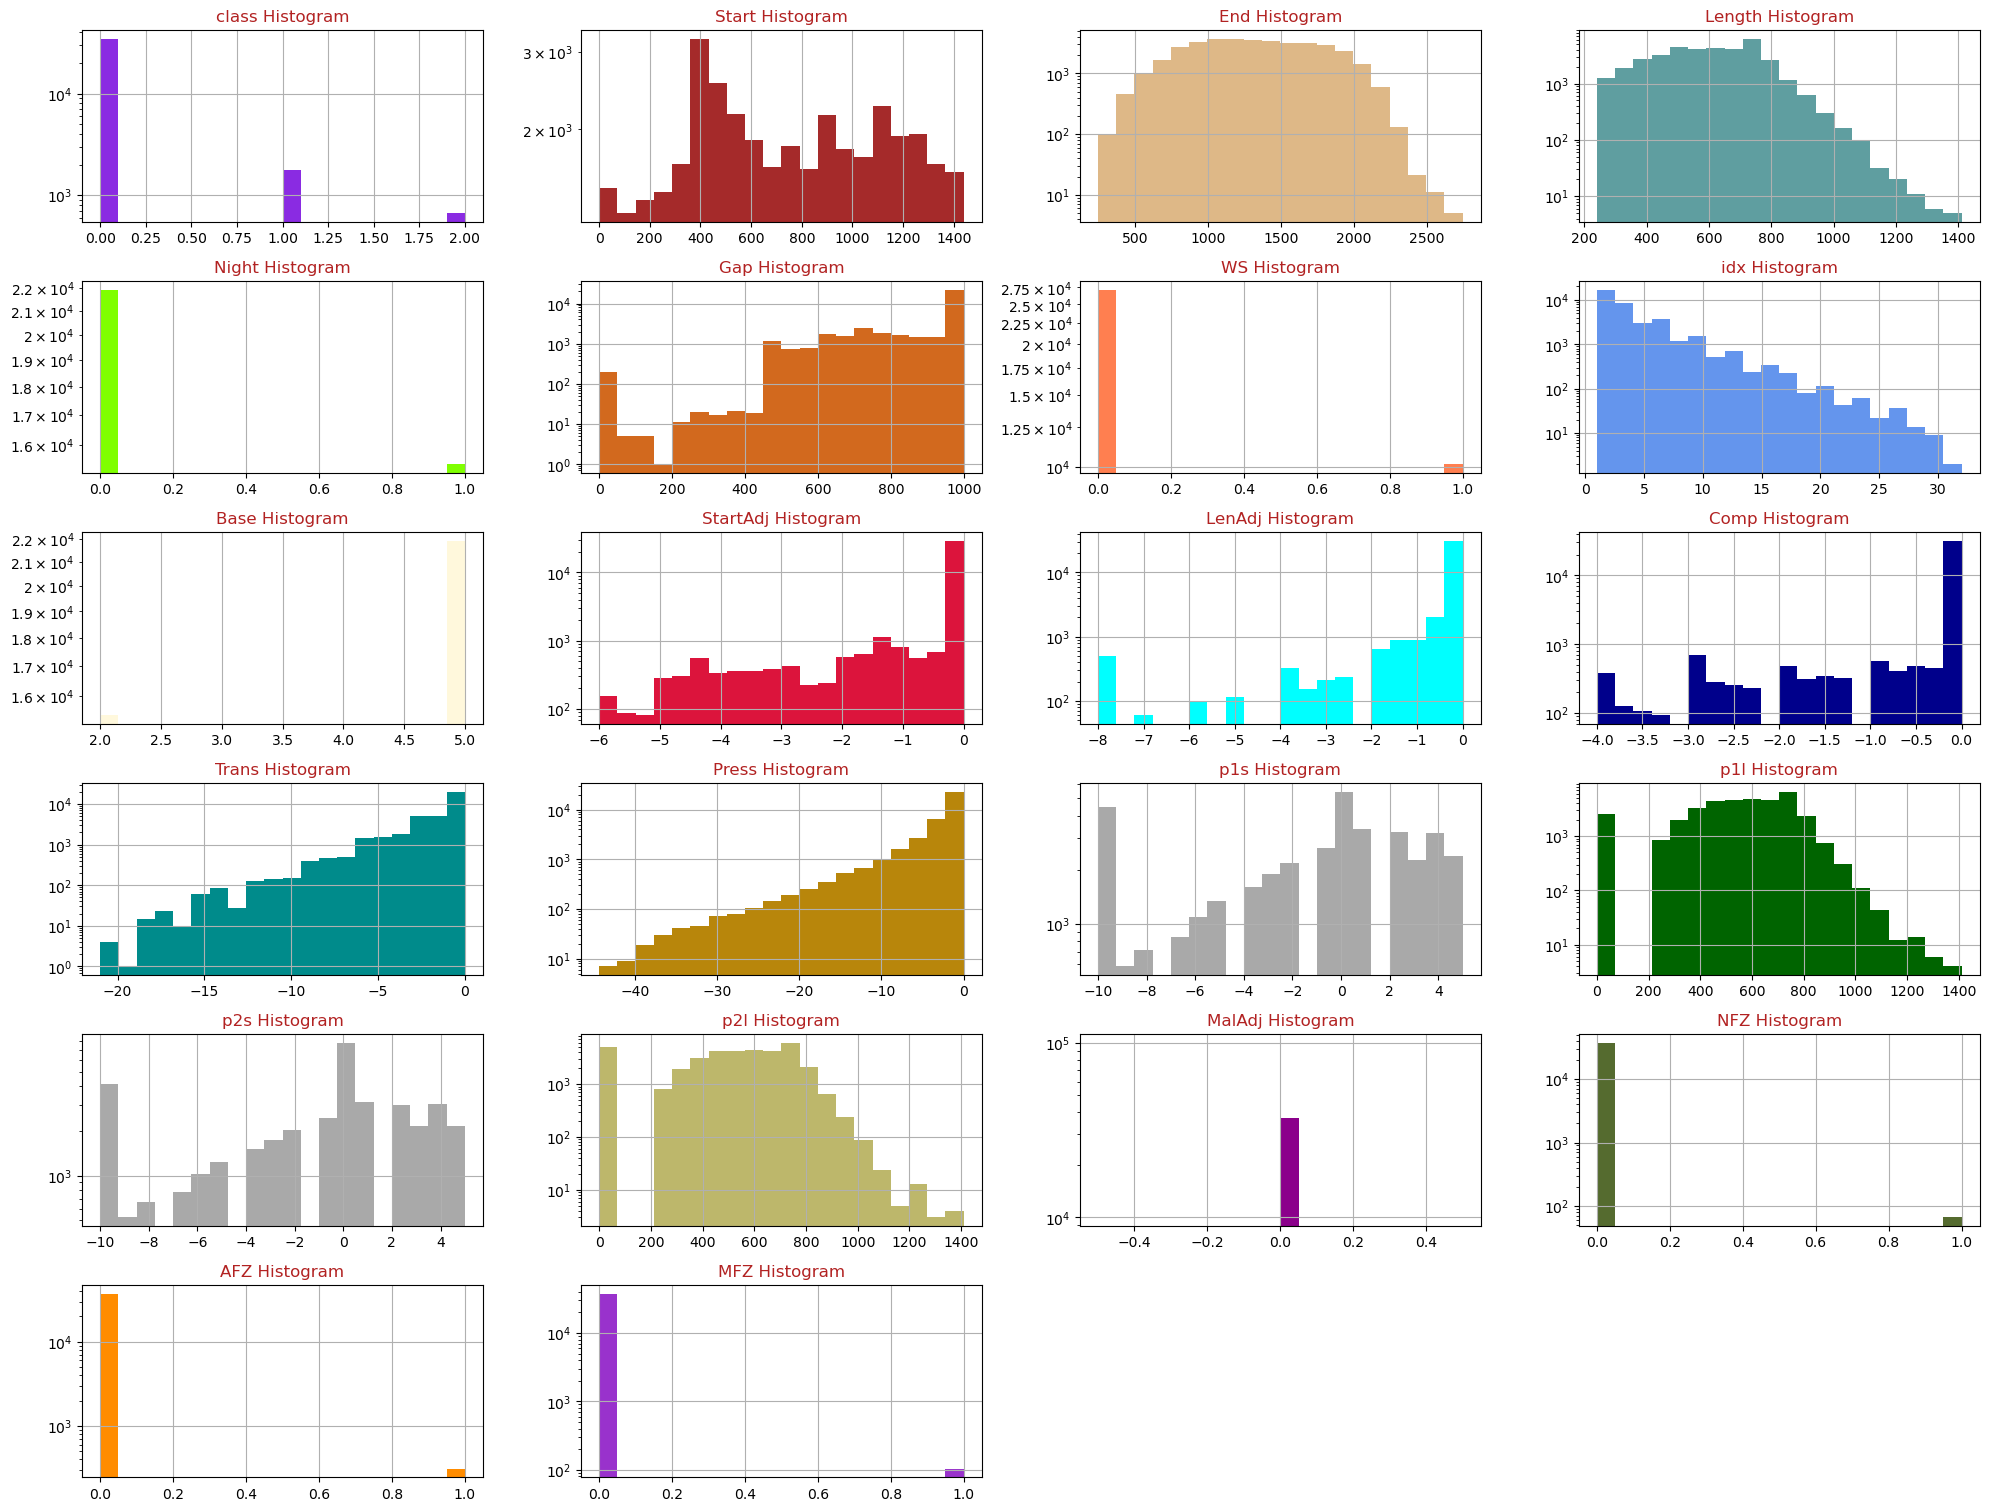

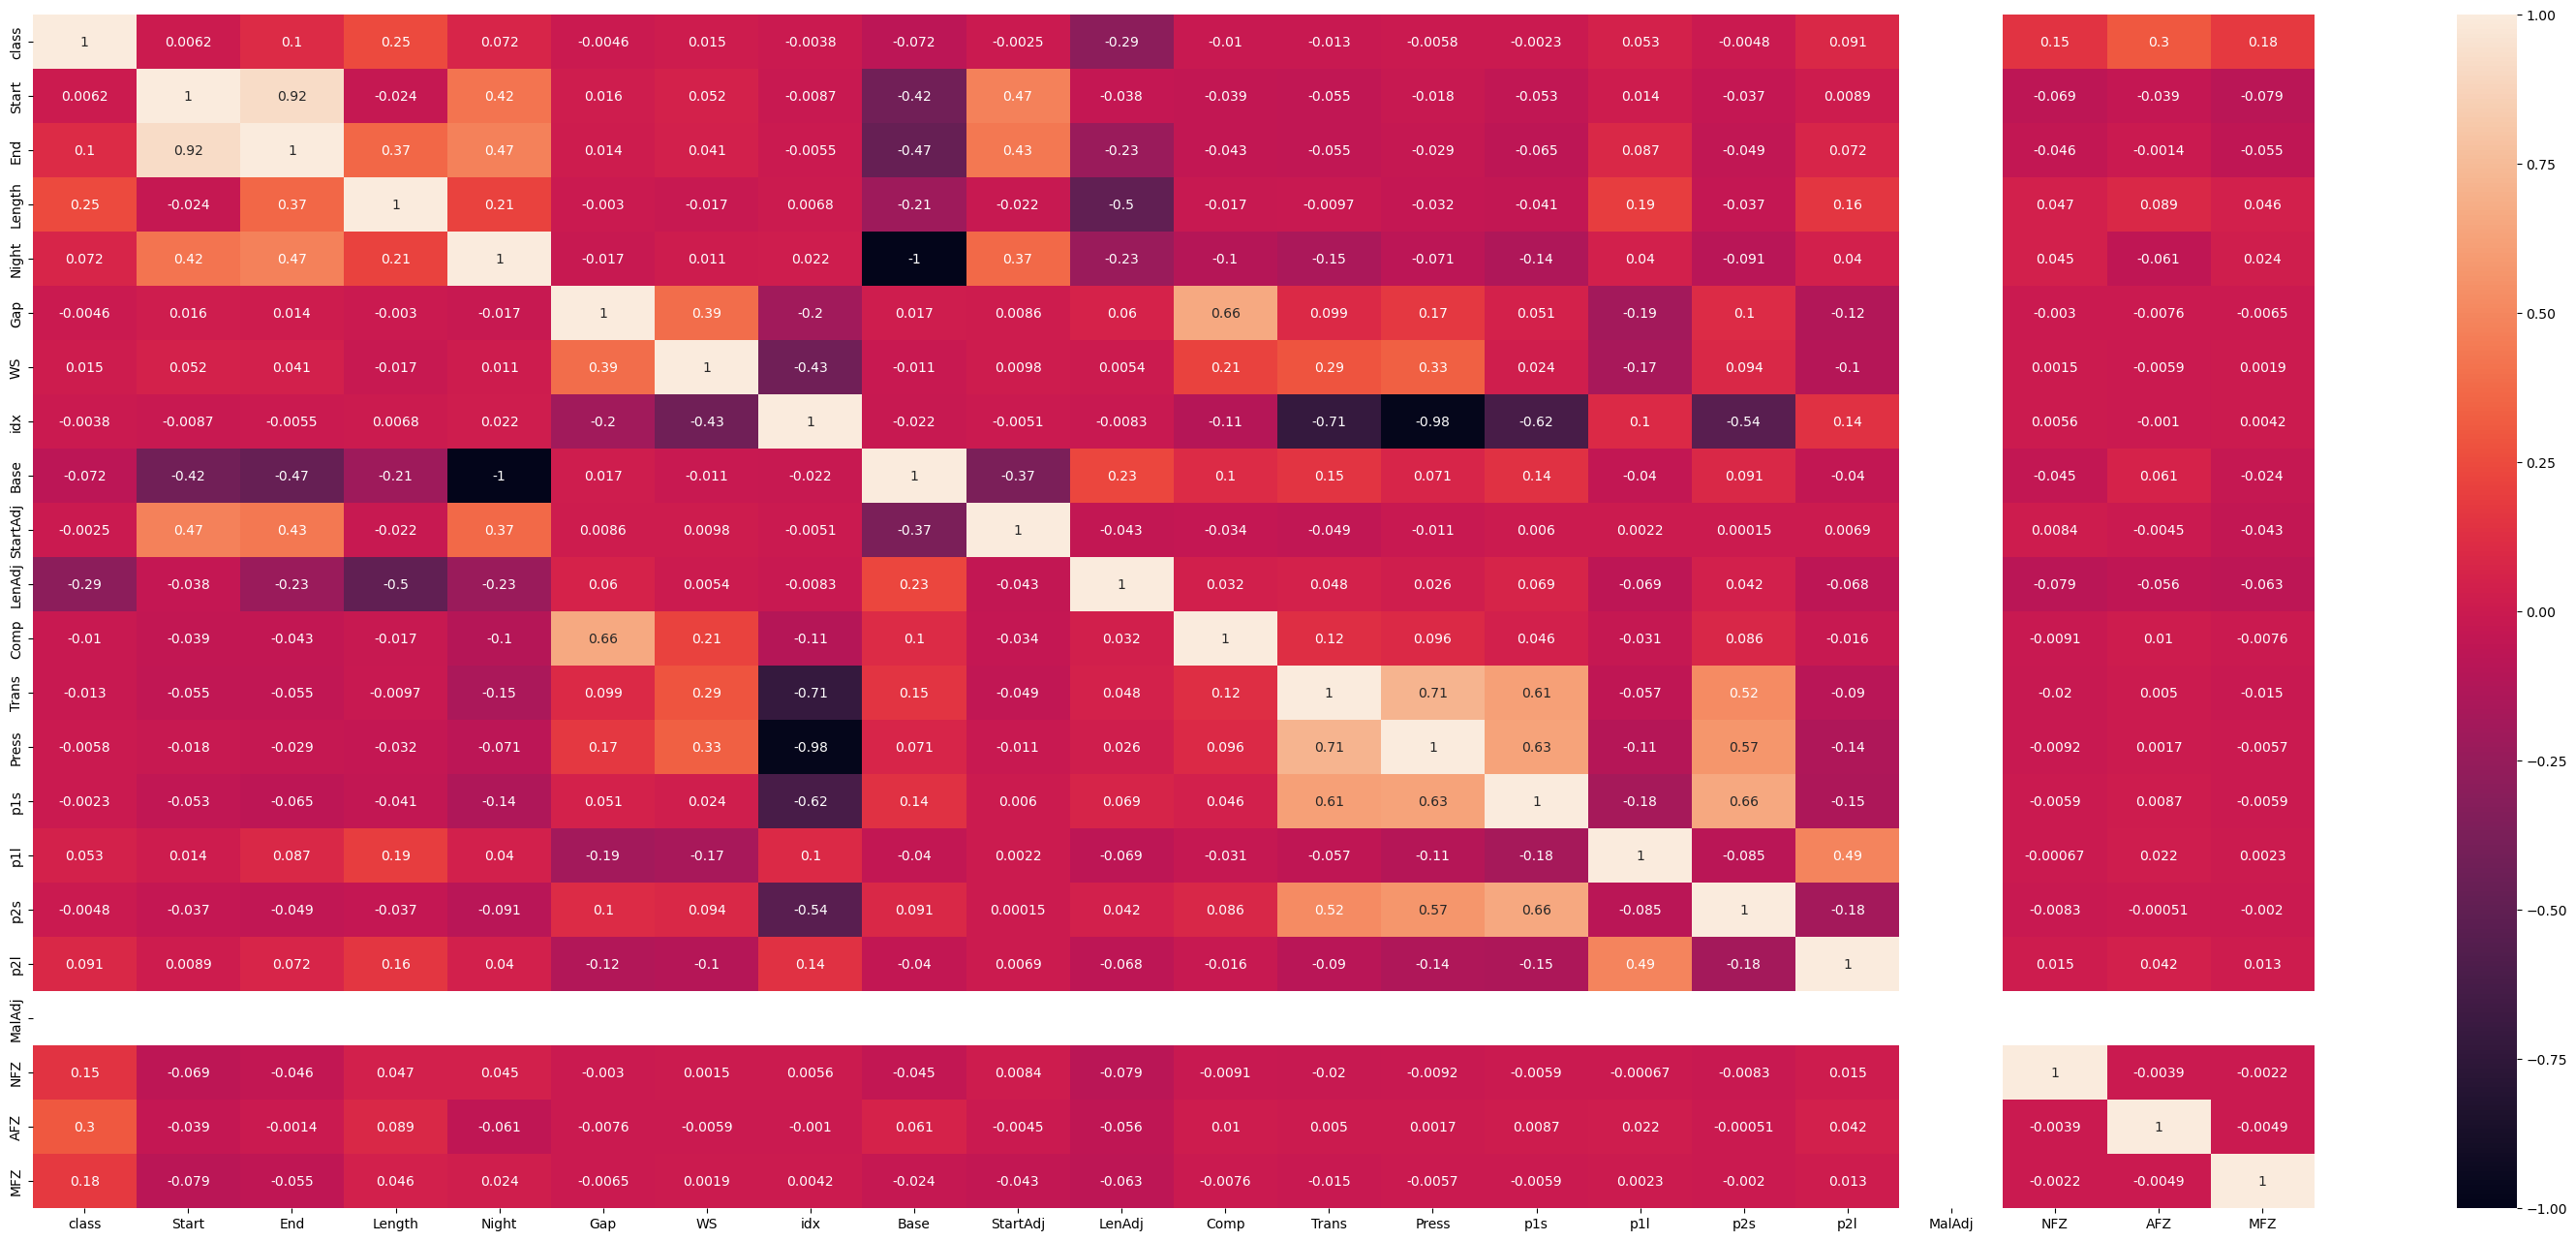

In [209]:
eda(df3b)

In [210]:
def scaling(X_train, X_test):
    scaler = preprocessing.StandardScaler().fit(X_train)
    X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns = X_train.columns)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns = X_test.columns)
    
    return X_train_scaled, X_test_scaled

# Binary Logistic Regression

We assume that both types of accidents are the same

In [211]:
def binary(X_train, X_test, y_train, y_test):
    X_train_scaled, X_test_scaled = scaling(X_train, X_test)
    
    model = LogisticRegression();
    model.fit(X_train_scaled, y_train)
    train_accuracy = model.score(X_train_scaled, y_train)
    print(f'The accuracy for the training set is {100 * train_accuracy:.2f}%')
    test_accuracy = model.score(X_test_scaled, y_test)
    print(f'The accuracy for the test set is {100 * test_accuracy:.2f}%')

# TODO: print ROC and CF Mat 
    probabilities = model.predict_proba(X_test_scaled)[:, 1]
# controlling thresholds? we want less false negatives
    probabilities = (probabilities >= 0.30)

    print("Confusion matrix:")
    print(confusion_matrix(y_test, probabilities))

In [212]:
# accuracies barely change when we take out Firm, for the binary version
binary(X_train1, X_test1, y_train1, y_test1)
binary(X_train3a, X_test3a, y_train3a, y_test3a)

The accuracy for the training set is 94.95%
The accuracy for the test set is 94.83%
Confusion matrix:
[[6885   88]
 [ 320  169]]
The accuracy for the training set is 94.94%
The accuracy for the test set is 94.97%
Confusion matrix:
[[6882   91]
 [ 308  181]]


We can test how this model performs if we remove the no accidents. If the model is performing poorly, then the two accidents are being guessed by the model. For example, removing accidents of type 0 would give us:

In [213]:
df2_only = df.copy()
df2_only = df[df["class"] != 0].copy()
print(df2_only["class"].value_counts())

y_acc = df2_only["class"]
X_acc = df2_only.drop(columns=["class"])

X_train_acc, X_test_acc, y_train_acc, y_test_acc = train_test_split(X_acc, y_acc, test_size=0.20, random_state=12, stratify=y_acc)

binary(X_train_acc, X_test_acc, y_train_acc, y_test_acc)

class
1    1779
2     665
Name: count, dtype: int64
The accuracy for the training set is 73.15%
The accuracy for the test set is 73.01%
Confusion matrix:
[[  0   0   0]
 [272  84   0]
 [ 92  41   0]]


# Multinomial Logistic Regression

We assume that each type of accident are distinct and non-ordered

In [214]:
def multi(X_train, X_test, y_train, y_test):
    X_train, X_test = scaling(X_train, X_test)
    
    multi_model = LogisticRegression()
    multi_model.fit(X_train, y_train)
    # print(multi_model.classes_)

    probs = multi_model.predict_proba(X_test)[:1]
    # print(probs[:10])

    accuracy = multi_model.predict(X_test)
    print(f"The accuracy for the multinomial model is: {round(accuracy_score(y_test, accuracy),3)}")


# TODO: print ROC and CF Mat 
    cm = confusion_matrix(y_test, accuracy)
    print("Actual 0: ", cm[0])
    print("Actual 1: ", cm[1])
    print("Actual 2: ", cm[2])

# TODO: feature importance
    coefficients = pd.DataFrame(multi_model.coef_)
    # print(coefficients)

    # Overall feature importance
    # take average of each coefficient SIZE from each feature from every class
    feature_importance = pd.DataFrame({"Feature": X_train.columns, "Importance": np.abs(multi_model.coef_).mean(axis=0)})

    print(feature_importance.sort_values("Importance",ascending=False))

In [215]:
# multi(X_train1, X_test1, y_train1, y_test1)
multi(X_train2, X_test2, y_train2, y_test2)
# multi(X_train3a, X_test3a, y_train3a, y_test3a)
# multi(X_train3b, X_test3b, y_train3b, y_test3b)

The accuracy for the multinomial model is: 0.943
Actual 0:  [6949   24    0]
Actual 1:  [264  91   1]
Actual 2:  [107  26   0]
     Feature  Importance
20       AFZ    0.479239
3     Length    0.339425
21       MFZ    0.272726
19       NFZ    0.224890
7        idx    0.145687
17       p2l    0.144087
13     Press    0.139625
2        End    0.124272
10    LenAdj    0.106943
0       FIRM    0.098427
9   StartAdj    0.088940
12     Trans    0.070075
14       p1s    0.068309
6         WS    0.066422
1      Start    0.042141
11      Comp    0.032515
8       Base    0.030812
4      Night    0.030812
5        Gap    0.021005
16       p2s    0.012310
15       p1l    0.006151
18    MalAdj    0.000000


In [216]:
# multi(X_train1, X_test1, y_train1, y_test1)
# multi(X_train2, X_test2, y_train2, y_test2)
# multi(X_train3a, X_test3a, y_train3a, y_test3a)
multi(X_train3b, X_test3b, y_train3b, y_test3b)

The accuracy for the multinomial model is: 0.943
Actual 0:  [6949   24    0]
Actual 1:  [264  91   1]
Actual 2:  [107  26   0]
     Feature  Importance
19       AFZ    0.476481
2     Length    0.339535
20       MFZ    0.270137
18       NFZ    0.223411
16       p2l    0.143239
1        End    0.123728
12     Press    0.119807
9     LenAdj    0.091396
13       p1s    0.086270
5         WS    0.082861
6        idx    0.082167
8   StartAdj    0.066726
11     Trans    0.056805
0      Start    0.040867
10      Comp    0.035337
7       Base    0.031575
3      Night    0.031575
4        Gap    0.029120
15       p2s    0.012239
14       p1l    0.010553
17    MalAdj    0.000000


For the binary class, the binary model and multinomial models are outputting the same accuracies.

if time permits, I will also do Ordinal. For now, we have binary and multinomial.

In [217]:
# TODO: feature importance
 

# Answering the Questions:

**The first question we would like answered is this: Are the two types of accident distinguishable?  Is there a fairly reliable way to tell these apart?**

Yes but only slightly. Running a binary logistic regression tells us this. If the model was guessing, the model would perform poorly at distinguishing between either type of accident.

Our model had a test and training accuracy of 73%. MEaning it is slightly indistinguishable but not too much that the model is able to perform better.

I believe that the two accidents are quite similar, but one of them is a "worse" type of accident. Through this, I believe we should run an ordinal logistic regression.



**The second question (which depends upon the answer to the first!) is this: How accurately does the regressor classify the samples?  Graphs and numbers may be interesting here, but a confusion matrix would be helpful.  If you determine that the two classes are indistinguishable, that there is only one type of accident, then the simple confusion matrix suffices.  But if you determine that the types are distinguishable, then we either need 3 confusion matrices (No accident vs type 1, No accident vs type 2, and type 1 vs type 2), or if you can, a 3-way confusion matrix.**

In the multinomial logistic, we get an accuracy of 94.3% for both data sets, one from the original, and the other without the column "FIRM". 

The accuracy for the multinomial model is: 0.943
Our 3-way confusion matrix is the following:

Actual 0:  [6949   24    0] 

Actual 1:  [264  91   1] 

Actual 2:  [107  26   0] 



**The third question is this: Which of the features (input columns) are significant in performing the classification, and which can/should be ignored?**

The Feature Importance Is:

     Feature  Importance

20       AFZ    0.479239

3     Length    0.339425

21       MFZ    0.272726

19       NFZ    0.224890

7        idx    0.145687

17       p2l    0.144087

13     Press    0.139625

2        End    0.124272

10    LenAdj    0.106943

0       FIRM    0.098427